# Prevendo quais clientes vão parar de comprar (churn) 

**Base de dados:** Online Retail (UCI Machine Learning Repository) — compras de uma loja online do Reino Unido entre dez/2010 e dez/2011.

**O que eu quero descobrir:** olhando o histórico de compras de um cliente, será que ele **volta a comprar** nos próximos meses ou **vai embora** (churn)?
Isso é útil porque a loja poderia mandar um cupom só para quem está em risco de sair.

É um problema de **classificação**: a resposta é 0 (voltou a comprar) ou 1 (churn).

**Etapas deste notebook**
1. Carregar a base
2. Estatísticas descritivas
3. Transformações nas linhas
4. Transformações nas colunas
5. Montar a tabela de clientes e a coluna que quero prever
6. Separar em treino, validação e teste
7. Treinar e avaliar o modelo
8. Matriz de confusão e acurácia
9. Fazer uma predição

## 1. Carregando a base

Primeiro importo as bibliotecas. Depois carrego o arquivo. Se você estiver no Google Colab e o arquivo ainda não estiver lá, vai aparecer um botão para **enviar o `online_retail.zip`**.

In [1]:
import os, zipfile
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

In [2]:
# Procura o arquivo; se não achar (Colab), pede para enviar o .zip
if not os.path.exists("Online Retail.xlsx"):
    zips = [f for f in os.listdir(".") if f.lower().endswith(".zip")]
    if not zips:
        from google.colab import files
        files.upload()   # escolha o arquivo .zip da base
        zips = [f for f in os.listdir(".") if f.lower().endswith(".zip")]
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(".")

# Essa leitura demora cerca de 1 minuto (são mais de 500 mil linhas)
df_original = pd.read_excel("Online Retail.xlsx")
print("Linhas e colunas:", df_original.shape)
df_original.head()

Linhas e colunas: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Cada linha é um item comprado. As colunas são: número da fatura (`InvoiceNo`), código e nome do produto (`StockCode`, `Description`), quantidade (`Quantity`), data (`InvoiceDate`), preço unitário (`UnitPrice`), id do cliente (`CustomerID`) e país (`Country`).

## 2. Estatísticas descritivas

Antes de mexer em qualquer coisa, quero conhecer a base: tipos das colunas, médias, valores faltando, etc.

In [3]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [4]:
# Resumo estatístico das colunas numéricas (média, desvio, mínimo, máximo...)
df_original[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [5]:
# Quantos valores estão faltando, quantas linhas repetidas e quantos valores estranhos
print("Valores faltando por coluna:")
print(df_original.isna().sum())
print()
print("Linhas duplicadas:", df_original.duplicated().sum())
print("Linhas com quantidade <= 0:", (df_original["Quantity"] <= 0).sum())
print("Linhas com preço <= 0:", (df_original["UnitPrice"] <= 0).sum())

Valores faltando por coluna:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64



Linhas duplicadas: 5268
Linhas com quantidade <= 0: 10624
Linhas com preço <= 0: 2517


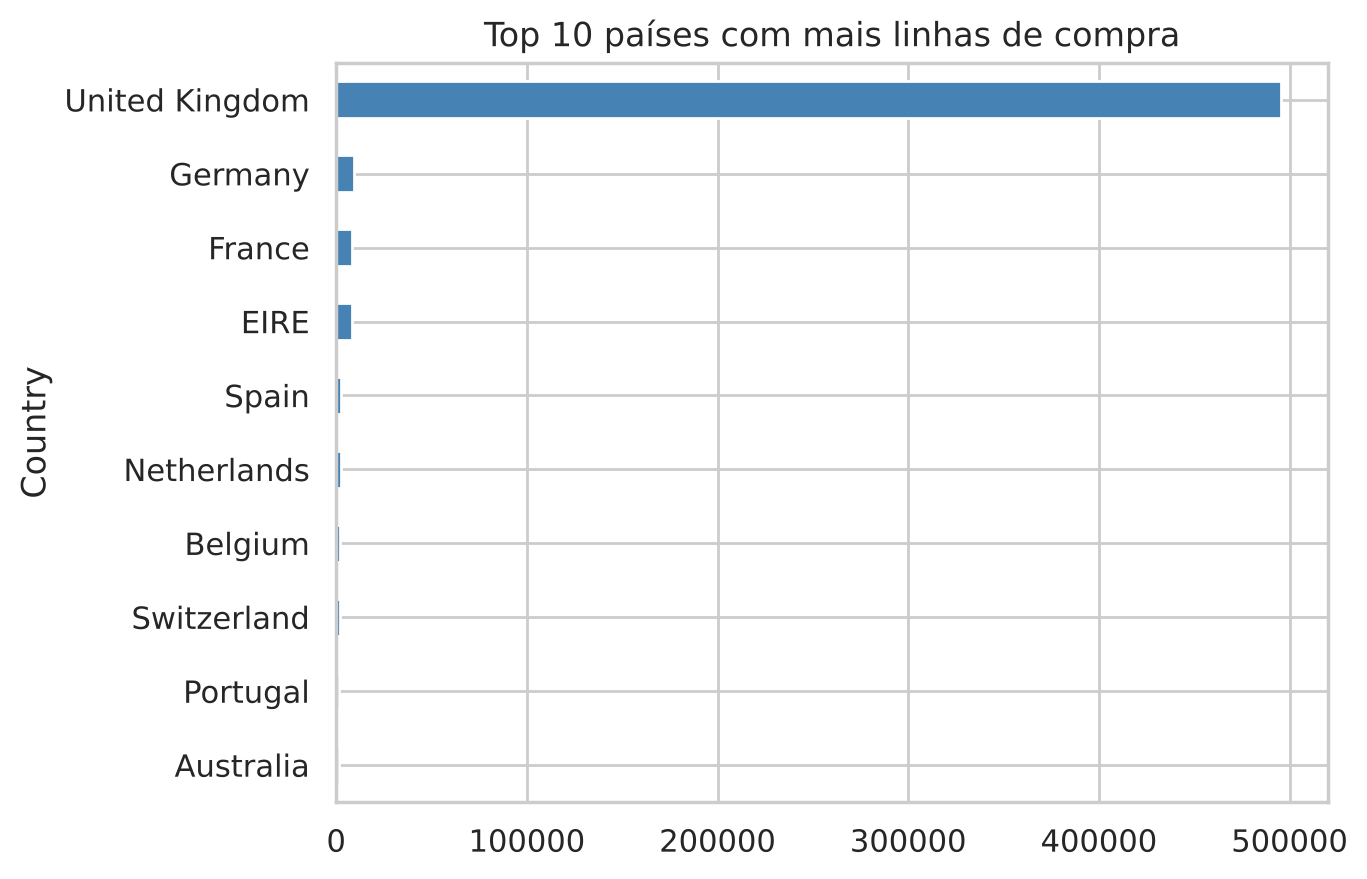

In [6]:
# Países com mais compras
df_original["Country"].value_counts().head(10).plot(kind="barh", color="steelblue")
plt.title("Top 10 países com mais linhas de compra")
plt.gca().invert_yaxis()
plt.show()

**O que eu percebi:**
- Cerca de 25% das linhas **não têm `CustomerID`**. Sem saber quem é o cliente, não consigo estudar o comportamento dele.
- Tem **quantidade negativa** (devoluções/cancelamentos), **preço zero** e **linhas repetidas**.
- A maioria das compras é do **Reino Unido**.

## 3. Transformações nas linhas

Aqui eu **removo linhas** que atrapalhariam o modelo:
1. sem `CustomerID`;
2. repetidas;
3. com quantidade ou preço menores ou iguais a zero (devoluções e erros).

In [7]:
df = df_original.copy()
print("Antes:", len(df), "linhas")

df = df.dropna(subset=["CustomerID"])                 # 1. sem cliente
df = df.drop_duplicates()                             # 2. repetidas
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)] # 3. quantidade/preço inválidos

print("Depois:", len(df), "linhas")

Antes: 541909 linhas


Depois: 392692 linhas


## 4. Transformações nas colunas

- `CustomerID` está como número com vírgula (17850.0) → vou converter para **inteiro**.
- Vou **criar** a coluna `ValorTotal` = quantidade × preço.
- Vou **criar** a coluna `EhUK` (1 se o cliente é do Reino Unido, 0 se não), porque a coluna de país tem muitas categorias.
- Vou **remover** a `Description`, que é só texto e não vou usar.

In [8]:
df["CustomerID"] = df["CustomerID"].astype(int)
df["ValorTotal"] = df["Quantity"] * df["UnitPrice"]
df["EhUK"] = (df["Country"] == "United Kingdom").astype(int)
df = df.drop(columns=["Description"])

df.head()

,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,ValorTotal,EhUK
0,536365,85123A,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,1
1,536365,71053,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,1
2,536365,84406B,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,1
3,536365,84029G,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,1
4,536365,84029E,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,1


## 5. Montando a tabela de clientes e a coluna que quero prever

A base original tem **uma linha por item comprado**, mas eu quero prever **por cliente**. Então preciso de uma linha por cliente.

Para o modelo não "colar" olhando o futuro, eu divido o tempo em dois pedaços:

- **Até 31/08/2011** → uso para descrever o cliente (quando comprou, quanto gastou...).
- **De 01/09/2011 em diante** → uso só para saber se ele **voltou a comprar**.

A coluna que quero prever (`churn`) fica assim: **1** se o cliente **não comprou** depois de 01/09, e **0** se comprou.

In [9]:
corte = pd.Timestamp("2011-09-01")
passado = df[df["InvoiceDate"] < corte]
futuro  = df[df["InvoiceDate"] >= corte]

# Uma linha por cliente, usando só o passado
por_cliente = passado.groupby("CustomerID")

clientes = pd.DataFrame({
    "dias_desde_ultima_compra": (corte - por_cliente["InvoiceDate"].max()).dt.days,
    "qtd_compras":              por_cliente["InvoiceNo"].nunique(),
    "valor_total_gasto":        por_cliente["ValorTotal"].sum(),
    "qtd_produtos_diferentes":  por_cliente["StockCode"].nunique(),
    "EhUK":                     por_cliente["EhUK"].first(),
})
clientes["ticket_medio"] = clientes["valor_total_gasto"] / clientes["qtd_compras"]

# Alvo: 1 = não comprou mais (churn) | 0 = voltou a comprar
clientes["churn"] = (~clientes.index.isin(futuro["CustomerID"])).astype(int)

print("Clientes:", len(clientes))
print()
print(clientes["churn"].value_counts())
clientes.head()

Clientes: 3317

churn
0    1952
1    1365
Name: count, dtype: int64


,dias_desde_ultima_compra,qtd_compras,valor_total_gasto,qtd_produtos_diferentes,EhUK,ticket_medio,churn
CustomerID,,,,,,,
12346,225,1,77183.60,1,1,77183.600000,1
12347,29,5,2790.86,82,0,558.172000,0
12348,148,3,1487.24,22,0,495.746667,0
12350,210,1,334.40,17,0,334.400000,1
12352,162,5,1561.81,26,0,312.362000,0


In [10]:
# Uma olhada nos números finais da tabela de clientes
clientes.describe()

,dias_desde_ultima_compra,qtd_compras,valor_total_gasto,qtd_produtos_diferentes,EhUK,ticket_medio,churn
count,3317.000000,3317.000000,3317.000000,3317.000000,3317.000000,3317.000000,3317.000000
mean,92.142900,3.440760,1575.966292,49.088031,0.901115,399.430318,0.411516
std,76.687522,5.586463,5974.011671,66.187556,0.298552,1435.701109,0.492183
min,0.000000,1.000000,2.900000,1.000000,0.000000,2.900000,0.000000
25%,27.000000,1.000000,258.250000,13.000000,1.000000,168.202000,0.000000
50%,72.000000,2.000000,552.800000,29.000000,1.000000,283.495000,0.000000
75%,146.000000,4.000000,1355.110000,62.000000,1.000000,412.648000,1.000000
max,273.000000,127.000000,176355.940000,1190.000000,1.000000,77183.600000,1.000000


Pronto: agora tenho uma tabela com **uma linha por cliente**, as colunas que descrevem o comportamento dele e a coluna `churn`, que é o que o modelo vai tentar adivinhar.

## 6. Separando em treino, validação e teste

- **Treino (60%)**: o modelo aprende com esses clientes.
- **Validação (20%)**: uso para conferir como o modelo está indo enquanto ainda estou ajustando.
- **Teste (20%)**: guardo para o final, como uma "prova surpresa". O modelo nunca viu esses clientes.

Uso `stratify` para manter a mesma proporção de churn nos três conjuntos.

In [11]:
X = clientes.drop(columns=["churn"])   # características do cliente
y = clientes["churn"]                  # o que quero prever

# Primeiro tiro 20% para teste
X_resto, X_teste, y_resto, y_teste = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

# Dos 80% que sobraram, 25% viram validação (25% de 80% = 20% do total)
X_treino, X_valid, y_treino, y_valid = train_test_split(X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=42)

print("Treino    :", len(X_treino), "clientes")
print("Validação :", len(X_valid), "clientes")
print("Teste     :", len(X_teste), "clientes")

Treino    : 1989 clientes
Validação : 664 clientes
Teste     : 664 clientes


## 7. Treinando o modelo

Escolhi o **Random Forest** (floresta aleatória): ele cria várias árvores de decisão e junta o "voto" de todas. É simples de usar e costuma funcionar bem sem precisar de muito ajuste.

Depois de treinar, comparo a acurácia no treino com a da validação. Se a do treino fosse muito maior, o modelo estaria só "decorando" os dados.

In [12]:
modelo = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42)
modelo.fit(X_treino, y_treino)

acc_treino = accuracy_score(y_treino, modelo.predict(X_treino))
acc_valid  = accuracy_score(y_valid,  modelo.predict(X_valid))

print(f"Acurácia no treino    : {acc_treino:.1%}")
print(f"Acurácia na validação : {acc_valid:.1%}")

Acurácia no treino    : 73.6%
Acurácia na validação : 67.6%


In [13]:
# Para saber se o modelo vale a pena: e se eu chutasse sempre a classe mais comum?
mais_comum = y_treino.mode()[0]
acc_chute = (y_valid == mais_comum).mean()
print(f"Acurácia 'chutando sempre {mais_comum}' na validação: {acc_chute:.1%}")

Acurácia 'chutando sempre 0' na validação: 58.9%


Se o modelo ganha desse "chute", é sinal de que ele aprendeu algo útil sobre os clientes.

## 8. Resultado final: acurácia e matriz de confusão (conjunto de teste)

Agora sim uso o conjunto de **teste**, que o modelo nunca viu.

In [14]:
previsoes = modelo.predict(X_teste)
acuracia = accuracy_score(y_teste, previsoes)

print(f"ACURÁCIA NO TESTE: {acuracia:.1%}")

ACURÁCIA NO TESTE: 67.3%


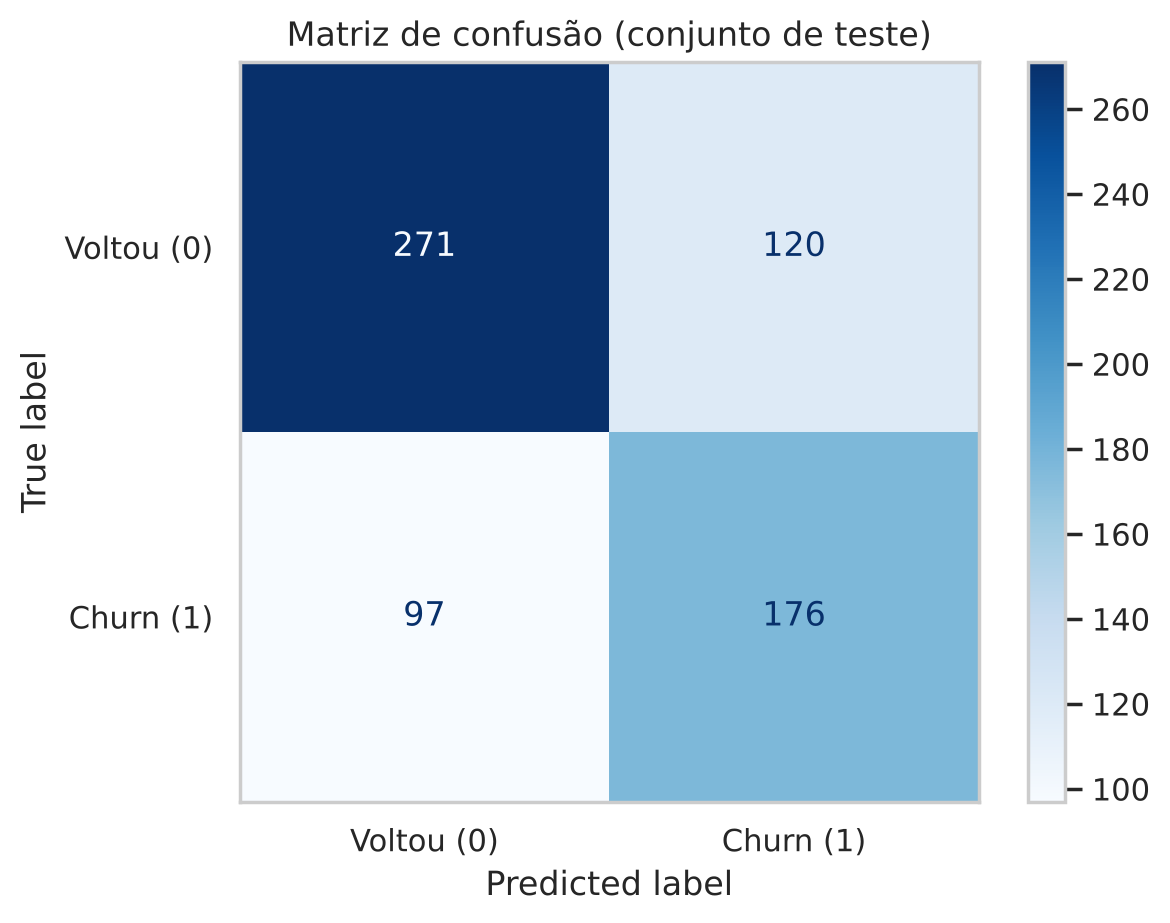

Previu 'voltou' e voltou:          271
Previu 'churn' mas o cliente voltou: 120
Previu 'voltou' mas o cliente saiu:  97
Previu 'churn' e o cliente saiu:     176


In [15]:
matriz = confusion_matrix(y_teste, previsoes)

ConfusionMatrixDisplay(matriz, display_labels=["Voltou (0)", "Churn (1)"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusão (conjunto de teste)")
plt.grid(False)
plt.show()

vn, fp, fn, vp = matriz.ravel()
print(f"Previu 'voltou' e voltou:          {vn}")
print(f"Previu 'churn' mas o cliente voltou: {fp}")
print(f"Previu 'voltou' mas o cliente saiu:  {fn}")
print(f"Previu 'churn' e o cliente saiu:     {vp}")

**Como ler a matriz:** a diagonal (de cima à esquerda até embaixo à direita) são os **acertos**. Os outros dois quadrados são os **erros**.
O pior erro para a loja é o de **"previu que voltaria, mas o cliente saiu"**, porque ele não receberia nenhum cupom de retenção.

## 9. Implantando o modelo e fazendo uma predição

Para simular a **implantação**, eu salvo o modelo treinado em um arquivo e carrego esse arquivo de volta, do mesmo jeito que um sistema de verdade faria para usar o modelo depois.

Em seguida invento um cliente novo e pergunto ao modelo carregado se ele corre risco de sair.

In [16]:
joblib.dump(modelo, "modelo_churn.joblib")            # salva o modelo em arquivo
modelo_implantado = joblib.load("modelo_churn.joblib") # carrega o modelo salvo
print("Modelo salvo e carregado com sucesso!")

Modelo salvo e carregado com sucesso!


In [17]:
novo_cliente = pd.DataFrame([{
    "dias_desde_ultima_compra": 150,   # faz 5 meses que ele não compra
    "qtd_compras": 1,                  # comprou só uma vez
    "valor_total_gasto": 120.0,
    "qtd_produtos_diferentes": 8,
    "EhUK": 1,
    "ticket_medio": 120.0,
}])

resposta = modelo_implantado.predict(novo_cliente)[0]
chance = modelo_implantado.predict_proba(novo_cliente)[0][1]

print("Previsão:", "CHURN (vai parar de comprar)" if resposta == 1 else "VOLTA A COMPRAR")
print(f"Chance de churn: {chance:.1%}")

Previsão: CHURN (vai parar de comprar)
Chance de churn: 69.1%


In [18]:
# Agora um cliente bem diferente: comprou várias vezes e comprou faz poucos dias
cliente_fiel = pd.DataFrame([{
    "dias_desde_ultima_compra": 10,
    "qtd_compras": 8,
    "valor_total_gasto": 3000.0,
    "qtd_produtos_diferentes": 70,
    "EhUK": 1,
    "ticket_medio": 375.0,
}])

resposta = modelo_implantado.predict(cliente_fiel)[0]
chance = modelo_implantado.predict_proba(cliente_fiel)[0][1]

print("Previsão:", "CHURN (vai parar de comprar)" if resposta == 1 else "VOLTA A COMPRAR")
print(f"Chance de churn: {chance:.1%}")

Previsão: VOLTA A COMPRAR
Chance de churn: 5.3%


## Conclusão

- Peguei a base Online Retail e montei uma tabela com **uma linha por cliente**.
- Limpei as linhas (sem cliente, repetidas, devoluções) e criei/converti colunas.
- Separei em **treino, validação e teste**, treinei um **Random Forest** e avaliei com **acurácia** e **matriz de confusão**.
- Salvei o modelo, carreguei de volta (implantação) e fiz predições com ele.
- O modelo fica acima do "chute" da classe mais comum, mas não é perfeito. Faz sentido: eu só tenho um ano de dados e muitos clientes compraram uma vez só.
- Para melhorar no futuro eu poderia testar outros modelos e criar mais características dos clientes.

**Fonte dos dados:** Chen, D. (2015). *Online Retail*. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33